In [24]:
# notebooks/result_processing.ipynb

# ---
# # Experiment Results Analysis
# This notebook orchestrates the loading, analysis, and reporting of experiment
# results logged to Weights & Biases.
# ---

# ## 1. Setup and Imports
# Import necessary libraries and custom modules. The `sys.path.append` line
# allows the notebook to find the custom `picid_report` package.
import sys
import pandas as pd

sys.path.append("..")

from picid_report.core import load_runs_df
from picid_report.core import analyze_results
from picid_report.report import create_summary_table

import seaborn as sns

%load_ext autoreload
%autoreload 2

# ---
# ## 2. Configuration
# Define all key parameters for the analysis in one place.
# ---


# PROJECT_NAME = "xjtu_sy_full"
# PROJECT_NAME = "nb14_full"
# PROJECT_NAME = "unibo_full"
PROJECT_NAME = "n_cmapss_scaling"
PROJECT_NAME = "16_02_2026_scaling_blockwise_new_evaluator_phme20_prognostics_raw"
PROJECT_NAME = "16_02_2026_scaling_blockwise_phme20_prognostics_raw"
PROJECT_NAME = "16_02_2026_scaling_phme20_prognostics_raw"

# PROJECT_NAME = "n_cmapss_final"
# PROJECT_NAME = "TabPFN_ds02_sweep_2025_10_09"
# PROJECT_NAME = "railway_traction_final"
# PROJECT_NAME = "phme20_full"
USER = "imos-buildingenergy-1"

METRIC_PREFIXES = [
    # "val/",
    "test/"
]
REPORTING_METRICS = [
    # "loss",
    "mse",
    "mae",
    "rmse",
    "mse_normalized",
    "mae_normalized",
    "rmse_normalized",
    "mse_denormalized",
    "mae_denormalized",
    "rmse_denormalized",
]


REPORTING_METRICS_BATTERY = [f"{r}_mean" for r in REPORTING_METRICS] + [
    "phme_score_mean"
]


# Configure pandas display options for better readability in the notebook.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ---
# ## 3. Data Loading
# Fetch data from wandb (or a local cache) and prepare the initial DataFrame.
# The `load_runs_df` function handles all the complex cleaning and flattening.
# ---
df, config_columns, dropped_columns = load_runs_df(project_name=PROJECT_NAME, user=USER)

# ---
# ## 4. Core Analysis
# Run the main analysis function to group results by dataset and model,
# find the best hyperparameter configuration, and collect performance metrics.
# ---

if "nb14" in PROJECT_NAME or "unibo" in PROJECT_NAME:
    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS_BATTERY,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_mean",
        optimization_mode="min",
    )

elif "n_cmapss" in PROJECT_NAME:
    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_denormalized",
        optimization_mode="min",
    )

else:
    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_normalized",
        optimization_mode="min",
    )

# ---
# ## 5. Generate and Display Summary
# Create the final pivoted summary table for a high-level overview
# of the best performance for each model on each dataset.
# ---
summary_df = create_summary_table(all_results, precision=3)
summary_df.index = (
    summary_df.index.str.split(".").str[-1].str.replace("_", "-")
)  # Simplify model names

print("\n📊 Final Performance Summary Table:")
display(summary_df)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Load: project=16_02_2026_scaling_phme20_prognostics_raw, user=imos-buildingenergy-1, cache_dir=csv_files
Loaded 812 runs from cached file: csv_files/16_02_2026_scaling_phme20_prognostics_raw.csv
Dropped 142 columns with >90% NaN
Dropped 60 columns by name filters
Analyze: 1 dataset(s), 11 model(s) -> 11 (dataset, model) combinations
  [WARNING] Hidden variation detected in 'test_best_rerun/nasa_score_denormalized'! (Varies within grouped config)
  PHME20 | lmetk.baselines.tide_model.TiDE_Forecaster: opt=test/mae_normalized mode=min grid=auto sort=test/mae_normalized runs=65 configs_failed_seed=0 configs_failed_invalid_metric=0
  [WARNING] Hidden variation detected in 'test_best_rerun/nasa_score_denormalized'! (Varies within grouped config)
  PHME20 | lmetk.baselines.patchtst_model.PatchTST_Forecaster: opt=test/mae_normalized mode=min grid=auto sort=test/mae_normalized runs=65 configs_failed_seed=0 c

Dataset                                         PHME20                                                                                                                                    \
Metric                                       test/loss  test/mae_denormalized  test/mae_normalized     test/mse_denormalized  test/mse_normalized           test/nasa_score_denormalized   
Model                                                                                                                                                                                      
Crossformer-Forecaster             0.002 ± 0.000 (n=5)   12.182 ± 1.231 (n=5)  0.034 ± 0.003 (n=5)    255.764 ± 48.614 (n=5)  0.002 ± 0.000 (n=5)                  23.832 ± 27.275 (n=5)   
LSTM-Forecaster                    0.002 ± 0.000 (n=6)   10.726 ± 1.402 (n=6)  0.030 ± 0.004 (n=6)    217.513 ± 46.773 (n=6)  0.002 ± 0.000 (n=6)                   10.864 ± 2.549 (n=6)   
PatchTST-Forecaster                0.042 ± 0.001 (n=5)   59.138 ± 0.413 (n=5)  0.167 ± 0.001 (n=5)   5316.707 ± 91.182 (n=5)  0.042 ± 0.001 (n=5)  2126097121.300 ± 4699266726.273 (n=5)   
Spacetimeformer-Forecaster         0.001 ± 0.000 (n=5)    9.906 ± 0.901 (n=5)  0.028 ± 0.003 (n=5)    175.420 ± 25.440 (n=5)  0.001 ± 0.000 (n=5)                    5.179 ± 1.535 (n=5)   
TiDE-Forecaster                    0.002 ± 0.001 (n=5)   10.477 ± 2.559 (n=5)  0.030 ± 0.007 (n=5)    202.187 ± 80.454 (n=5)  0.002 ± 0.001 (n=5)                    8.659 ± 4.074 (n=5)   
Timeseries-Transformer-Forecaster  0.001 ± 0.000 (n=5)    9.580 ± 1.210 (n=5)  0.027 ± 0.003 (n=5)    162.014 ± 38.979 (n=5)  0.001 ± 0.000 (n=5)                    5.377 ± 1.745 (n=5)   
CNN1D-Wrapper                      0.012 ± 0.007 (n=6)  30.099 ± 10.704 (n=6)  0.085 ± 0.030 (n=6)  1484.625 ± 859.548 (n=6)  0.012 ± 0.007 (n=6)              1825.449 ± 3675.679 (n=6)   
FitPredictTabDPTWrapper            1.000 ± 0.000 (n=1)    7.632 ± 0.000 (n=1)  0.022 ± 0.000 (n=1)     117.883 ± 0.000 (n=1)  0.001 ± 0.000 (n=1)                    4.079 ± 0.000 (n=1)   
FitPredictTabPFNWrapper            1.000 ± 0.000 (n=1)    6.257 ± 0.000 (n=1)  0.018 ± 0.000 (n=1)      69.580 ± 0.000 (n=1)  0.001 ± 0.000 (n=1)                    1.333 ± 0.000 (n=1)   
MLPWrapper                         0.002 ± 0.000 (n=5)   11.971 ± 0.875 (n=5)  0.034 ± 0.002 (n=5)    267.339 ± 31.994 (n=5)  0.002 ± 0.000 (n=5)          165789.824 ± 370458.053 (n=5)   
StatisticalBaselineWrapper         0.008 ± 0.001 (n=5)   26.325 ± 1.834 (n=5)  0.074 ± 0.005 (n=5)  1063.243 ± 156.487 (n=5)  0.008 ± 0.001 (n=5)                 115.078 ± 69.218 (n=5)   

Dataset                                                                                                   
Metric                            test/nasa_score_normalized test/rmse_denormalized test/rmse_normalized  
Model                                                                                                     
Crossformer-Forecaster                   0.003 ± 0.000 (n=5)   15.929 ± 1.592 (n=5)  0.045 ± 0.004 (n=5)  
LSTM-Forecaster                          0.003 ± 0.000 (n=6)   14.682 ± 1.532 (n=6)  0.041 ± 0.004 (n=6)  
PatchTST-Forecaster                      0.015 ± 0.000 (n=5)   72.914 ± 0.626 (n=5)  0.206 ± 0.002 (n=5)  
Spacetimeformer-Forecaster               0.003 ± 0.000 (n=5)   13.218 ± 0.938 (n=5)  0.037 ± 0.003 (n=5)  
TiDE-Forecaster                          0.003 ± 0.001 (n=5)   14.027 ± 2.605 (n=5)  0.040 ± 0.007 (n=5)  
Timeseries-Transformer-Forecaster        0.003 ± 0.000 (n=5)   12.662 ± 1.450 (n=5)  0.036 ± 0.004 (n=5)  
CNN1D-Wrapper                            0.008 ± 0.003 (n=6)  36.850 ± 12.330 (n=6)  0.104 ± 0.035 (n=6)  
FitPredictTabDPTWrapper                  0.002 ± 0.000 (n=1)   10.857 ± 0.000 (n=1)  0.031 ± 0.000 (n=1)  
FitPredictTabPFNWrapper                  0.002 ± 0.000 (n=1)    8.341 ± 0.000 (n=1)  0.024 ± 0.000 (n=1)  
MLPWrapper                               0.003 ± 0.000 (n=5)   16.327 ± 0.974 (n=5)

In [15]:
print(summary_df.to_latex())

\begin{tabular}{llllllllll}
\toprule
Dataset & \multicolumn{9}{r}{PHME20} \\
Metric & test/loss & test/mae_denormalized & test/mae_normalized & test/mse_denormalized & test/mse_normalized & test/nasa_score_denormalized & test/nasa_score_normalized & test/rmse_denormalized & test/rmse_normalized \\
Model &  &  &  &  &  &  &  &  &  \\
\midrule
Crossformer-Forecaster & 0.002 ± 0.000 (n=5) & 12.182 ± 1.231 (n=5) & 0.034 ± 0.003 (n=5) & 255.764 ± 48.614 (n=5) & 0.002 ± 0.000 (n=5) & 23.832 ± 27.275 (n=5) & 0.003 ± 0.000 (n=5) & 15.929 ± 1.592 (n=5) & 0.045 ± 0.004 (n=5) \\
LSTM-Forecaster & 0.002 ± 0.000 (n=6) & 10.726 ± 1.402 (n=6) & 0.030 ± 0.004 (n=6) & 217.513 ± 46.773 (n=6) & 0.002 ± 0.000 (n=6) & 10.864 ± 2.549 (n=6) & 0.003 ± 0.000 (n=6) & 14.682 ± 1.532 (n=6) & 0.041 ± 0.004 (n=6) \\
PatchTST-Forecaster & 0.042 ± 0.001 (n=5) & 59.138 ± 0.413 (n=5) & 0.167 ± 0.001 (n=5) & 5316.707 ± 91.182 (n=5) & 0.042 ± 0.001 (n=5) & 2126097121.300 ± 4699266726.273 (n=5) & 0.015 ± 0.000 (n=5) & 72.

For N-CMAPSS:

In [2]:
conflicts = df["test/mae"].notna() & df["test/mae_normalized"].notna()
print(conflicts.any(), df[conflicts].shape[0])

df["test/mae_normalized"] = df["test/mae_normalized"].combine_first(df["test/mae"])
df["test/rmse_normalized"] = df["test/rmse_normalized"].combine_first(df["test/rmse"])
df["test/mae_denormalized"] = df["test/mae_denormalized"].combine_first(df["test/mae"])
df["test/rmse_denormalized"] = df["test/rmse_denormalized"].combine_first(
    df["test/rmse"]
)

KeyError: 'test/mae'

For PHME20:

In [25]:
df_long = df[
    [
        "test/mae_normalized",
        "test/rmse_normalized",
        "test/mae_denormalized",
        "test/rmse_denormalized",
        "model._target_",
        "seed",
        "task_definition.subset_ratio",
        "task_definition.seq_len",
    ]
]
df_long
# df_long["ds"] = df["datasource.multisource_data_splitter.sources_train"].astype(str)

df_long = df_long.melt(
    id_vars=[
        "model._target_",
        "seed",
        "task_definition.subset_ratio",
        "task_definition.seq_len",
        # "ds"
    ],
    value_vars=[
        "test/mae_normalized",
        "test/rmse_normalized",
        "test/mae_denormalized",
        "test/rmse_denormalized",
    ],
    var_name="metric",
    value_name="value",
)
df_long


df_long = df_long[
    ~(
        (
            df_long["model._target_"]
            == "picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper"
        )
        & (df_long["task_definition.seq_len"] == 5)
    )
]
df_long.head()

,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value
0,lmetk.baselines.lstm_model.LSTM_Forecaster,72,0.001,20,test/mae_normalized,0.182596
1,lmetk.baselines.lstm_model.LSTM_Forecaster,72,0.005,20,test/mae_normalized,0.061644
2,lmetk.baselines.lstm_model.LSTM_Forecaster,72,0.010,20,test/mae_normalized,0.147283
3,lmetk.baselines.lstm_model.LSTM_Forecaster,72,0.050,20,test/mae_normalized,0.066153
4,lmetk.baselines.lstm_model.LSTM_Forecaster,72,0.100,20,test/mae_normalized,0.039476


In [43]:
labels

['LSTM',
 '1D-CNN',
 'TabDPT',
 'MLP',
 'StatBL',
 'STF',
 'CF',
 'TST',
 'TiDE',
 'PatchTST',
 'TabPFN']

In [45]:
inverse_rename

{'LSTM': 'lmetk.baselines.lstm_model.LSTM_Forecaster',
 '1D-CNN': 'lmetk.model.wrappers.cnn1d_wrapper.CNN1D_Wrapper',
 'MLP': 'lmetk.model.wrappers.mlp_wrapper.MLPWrapper',
 'StatBL': 'lmetk.model.wrappers.statistical_models_wrapper.StatisticalBaselineWrapper',
 'STF': 'lmetk.baselines.spacetimeformer_model.Spacetimeformer_Forecaster',
 'CF': 'lmetk.baselines.crossformer_model.Crossformer_Forecaster',
 'TST': 'lmetk.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster',
 'TiDE': 'lmetk.baselines.tide_model.TiDE_Forecaster',
 'PatchTST': 'lmetk.baselines.patchtst_model.PatchTST_Forecaster',
 'TabPFN': 'lmetk.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper',
 'TabDPT': 'lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper'}

/var/folders/8w/nzvg2wnj1vg1xcs7s2d8097j3kqzdw/T/ipykernel_60119/1909691898.py:61: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0.0, 1.0)


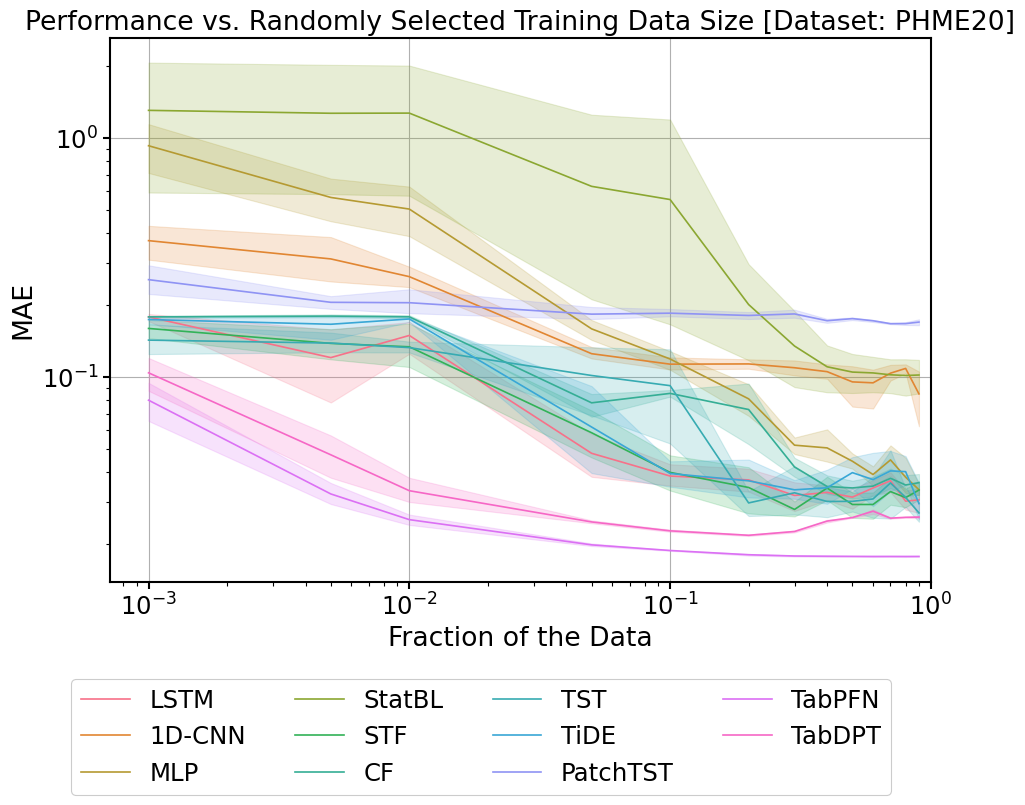

In [57]:
from matplotlib import pyplot as plt

with sns.plotting_context("paper", font_scale=2, rc={"font.family": "Helvetica"}):
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 7))

    variable_rename = {
        "lmetk.baselines.lstm_model.LSTM_Forecaster": "LSTM",
        "lmetk.model.wrappers.cnn1d_wrapper.CNN1D_Wrapper": "1D-CNN",
        "lmetk.model.wrappers.mlp_wrapper.MLPWrapper": "MLP",
        "lmetk.model.wrappers.statistical_models_wrapper.StatisticalBaselineWrapper": "StatBL",
        "lmetk.baselines.spacetimeformer_model.Spacetimeformer_Forecaster": "STF",
        "lmetk.baselines.crossformer_model.Crossformer_Forecaster": "CF",
        "lmetk.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster": "TST",
        "lmetk.baselines.tide_model.TiDE_Forecaster": "TiDE",
        "lmetk.baselines.patchtst_model.PatchTST_Forecaster": "PatchTST",
        "lmetk.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper": "TabPFN",
        "lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper": "TabDPT",
    }

    if "n_cmapss" in PROJECT_NAME:
        plot_df = df_long[df_long["ds"] == df_long["ds"].unique()[1]]
        metric = "test/rmse_denormalized"
    elif "phme20" in PROJECT_NAME:
        plot_df = df_long
        metric = "test/mae_normalized"
    else:
        raise ValueError("Unknown project for plotting")

    plot_df.to_csv("scaling_laws_railway_mape.csv", index=False)

    def extract_handles_labels_title(ax):
        old_legend = ax.legend_
        handles = old_legend.legend_handles
        labels = [t.get_text() for t in old_legend.get_texts()]
        title = old_legend.get_title().get_text()
        old_legend.remove()
        return handles, labels, title
        # ax.legend(handles, labels, loc=new_loc, title=title, **kws)

    # dashes = {m: (2, 2) if m in ["cf-plan", "stf-plan", "tf-plan", "tide-plan"] else "" for m in ccdfs.variable.unique()}

    sns.lineplot(
        plot_df[
            plot_df["model._target_"].isin(variable_rename.keys())
            & (plot_df["metric"] == metric)
        ],
        x="task_definition.subset_ratio",
        y="value",
        hue="model._target_",
        hue_order=list(variable_rename.keys()),
        #  palette=palette, ax=ax, dashes=dashes, style="variable", alpha=1
    )
    # ax.set_yscale('log')

    ax.set_title(
        f"Performance vs. Randomly Selected Training Data Size (%) {PROJECT_NAME}"
    )
    ax.set_title(
        "Performance vs. Randomly Selected Training Data Size [Dataset: PHME20]"
    )
    ax.set_ylabel(metric)
    ax.set_xlabel("Fraction of the Data")
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.set_axisbelow(True)
    ax.set_xlim(0.0, 1.0)
    ax.grid()

    # Add a box around the plot
    for spine in ax.spines.values():
        spine.set_visible(True)  # Make all spines visible
        spine.set_linewidth(1.5)  # Adjust the box line width if needed
        spine.set_color("black")  # Set the color of the frame

    # Set tick indicators (tick marks) thickness to 1.5
    ax.tick_params(axis="x", width=1.5)  # X-axis tick indicators
    ax.tick_params(axis="y", width=1.5)  # Y-axis tick indicators

    ax.set_ylabel("MAE")

    handles, labels, title = extract_handles_labels_title(ax)
    labels = [variable_rename[l] for l in labels]

    legend = fig.legend(
        handles=handles,
        labels=labels,
        title="",
        loc="upper center",
        bbox_to_anchor=(0.5, 0.02),
        ncol=4,
        framealpha=1,
    )

    fig.tight_layout()
    # fig.savefig(f'picid_report_artifacts/scaling_laws_ncmapss_{metric.split("/")[1]}.pdf',
    #             dpi=300, transparent=True, bbox_extra_artists=(legend,), bbox_inches='tight')

In [9]:
plot_df[
    plot_df["model._target_"]
    == "picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabPFNWrapper"
]

,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value


In [3]:
for key in all_results.keys():
    print(f"Dataset key: {key}")
    for key_2 in all_results[key].keys():
        print(f"  Model key: {key_2}")
        for sub_key in all_results[key][key_2].keys():
            # if pd data frame then display the head only
            if isinstance(all_results[key][key_2][sub_key], pd.DataFrame):
                print(f"    {sub_key}:")
                display(all_results[key][key_2][sub_key].head(2))
            # if dict proceed with keys
            elif isinstance(all_results[key][key_2][sub_key], dict):
                # same for inside dict and repeat
                for inner_key in all_results[key][key_2][sub_key].keys():
                    # print the
                    if isinstance(
                        all_results[key][key_2][sub_key][inner_key], pd.DataFrame
                    ):
                        print(f"   {sub_key}   {inner_key}:")
                        display(all_results[key][key_2][sub_key][inner_key].head(2))
                    else:
                        print(
                            f" {sub_key}     {inner_key}: {all_results[key][key_2][sub_key][inner_key]}"
                        )

            else:
                print(f"    {sub_key}: {all_results[key][key_2][sub_key]}")

Dataset key: MultiSource_concepts_N-CMAPSS
  Model key: picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper
 best_hyperparameters     datasource.val1.window_size: 5
 best_hyperparameters     datasource.val2.window_size: 5
 best_hyperparameters     datasource.val3.window_size: 5
 best_hyperparameters     datasource.val4.window_size: 5
 best_hyperparameters     datasource.test1.window_size: 5
 best_hyperparameters     datasource.test2.window_size: 5
 best_hyperparameters     datasource.test3.window_size: 5
 best_hyperparameters     datasource.test4.window_size: 5
 best_hyperparameters     datasource.train1.window_size: 5
 best_hyperparameters     datasource.train2.window_size: 5
 best_hyperparameters     datasource.train3.window_size: 5
 best_hyperparameters     datasource.train4.window_size: 5
 best_hyperparameters     datasource.source_list.val1.window_size: 5
 best_hyperparameters     datasource.source_list.val2.window_size: 5
 best_hyperparameters     datasource.s

Model datasource.val1.window_size datasource.val2.window_size datasource.val3.window_size datasource.val4.window_size datasource.test1.window_size  \
                                                                                                                                                                                                    
2  picid.model.wrappers.fit_predict_tabdpt_wrappe...                           5                           5                           5                           5                            5   
3  picid.model.wrappers.fit_predict_tabdpt_wrappe...                           5                           5                           5                           5                            5   

  datasource.test2.window_size datasource.test3.window_size datasource.test4.window_size datasource.train1.window_size datasource.train2.window_size datasource.train3.window_size  \
                                                                                                                                                                                     
2                            5                            5                            5                             5                             5                             5   
3                            5                            5                            5                             5                             5                             5   

  datasource.train4.window_size datasource.source_list.val1.window_size datasource.source_list.val2.window_size datasource.source_list.val3.window_size datasource.source_list.val4.window_size  \
                                                                                                                                                                                                  
2                             5                                       5                                       5                                       5                                       5   
3                             5                                       5                                       5                                       5                                       5   

  datasource.source_list.test1.window_size datasource.source_list.test2.window_size datasource.source_list.test3.window_size datasource.source_list.test4.window_size  \
                                                                                                                                                                        
2                                        5                                        5                                        5                                        5   
3                                        5                                        5                                        5                                        5   

  datasource.source_list.train1.window_size datasource.source_list.train2.window_size datasource.source_list.train3.window_size datasource.source_list.train4.window_size task_definition.seq_len  \
                                                                                                                                                                                                    
2                                         5                                         5                                         5                                         5                       5   
3                                         5                                         5                                         5                                         5                       5   

  task_definition.stride_train val/loss           val/mse           val/mae           val/rmse           test/loss              test/mse            test/mae            test/rmse            \
                                   mean std count    mean std count    mean std count     m

    non_aggregated_df:


,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,test/loss,test/mae,test/mse,test/nasa_score,test/rmse,test_best_rerun/loss,test_best_rerun/mae,test_best_rerun/mse,test_best_rerun/nasa_score,test_best_rerun/rmse,train/loss_epoch,train/loss_step,train/mae,train/mse,train/nasa_score,train/rmse,trainer/global_step,val/loss,val/mae,val/mse,val/nasa_score,val/rmse,val_best_rerun/loss,val_best_rerun/mae,val_best_rerun/mse,val_best_rerun/nasa_score,val_best_rerun/rmse,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,d_x,d_ff,d_yc,d_yt,ts_in,device,factor,ts_out,base_lr,d_model,dropout,init_lr,n_heads,seg_len,verbose,baseline,e_layers,l2_coeff,mask_y_c,metadata,patience,win_size,task_type,use_revin,evaluators,decay_factor,warmup_steps,learning_rate,linear_window,decoder_embedding,use_seasonal_decomp,linear_shared_weights,scheduler_Loss_monitor,n_layers,dropout_p,hidden_dim,time_emb_dim,teacher_forcing_prob,lr-AdamW,d_layers,use_x_dim,include_x_t,transformer_args,norm,head_f,d_values,use_time,use_given,use_space,activation,dropout_ff,use_tt_dec,use_tt_enc,attn_factor,dropout_emb,dropout_qkv,max_seq_len,use_val_dec,use_val_enc,embed_method,pos_emb_type,time_emb_type,class_loss_imp,d_queries_keys,n_timefeatures,performer_relu,recon_loss_imp,use_final_norm,local_self_attn,start_token_len,attention_method,dropout_attn_out,global_self_attn,inverted_encoder,local_cross_attn,performer_kernel,attn_time_windows,global_cross_attn,timetable_emb_type,dropout_attn_matrix,recon_mask_drop_seq,recon_mask_skip_all,recon_mask_drop_full,recon_mask_max_seq_len,initial_downsample_convs,recon_mask_drop_standard,use_shifted_time_windows,performer_redraw_interval,intermediate_downsample_convs,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.val2.RUL,datasource.val2.mode,datasource.val2.n_DS,datasource.val2.path,datasource.val2.cruise,datasource.val2.stride,datasource.val2.scaling,datasource.val2._target_,datasource.val2.concepts,datasource.val2.data_name,datasource.val2.task_mode,datasource.val2.data_folder,datasource.val2.window_size,datasource.val2.group_by_unit,datasource.val2.load_arguments.mode,datasource.val2.load_arguments.n_DS,datasource.val2.load_arguments.units,datasource.val2.binary_concepts,datasource.val2.include_healthy,datasource.val2.subsampling_rate,datasource.val2.combined_concepts,datasource.val3.RUL,datasource.val3.mode,datasource.val3.n_DS,datasource.val3.path,datasource.val3.cruise,datasource.val3.stride,datasource.val3.scaling,datasource.val3._target_,datasource.val3.concepts,datasource.val3.data_name,datasource.val3.task_mode,datasource.val3.data_folder,datasource.val3.window_size,datasource.val3.group_by_unit,datasource.val3

  Model key: picid.model.wrappers.cnn1d_wrapper.CNN1D_Wrapper
 best_hyperparameters     datamodule.train_batch_size: 512
 best_hyperparameters     run_names: ['concepts_n_cmapss+prognostics+cnn_1d_d699bee0', 'concepts_n_cmapss+prognostics+cnn_1d_4f740e7c', 'concepts_n_cmapss+prognostics+cnn_1d_9e6fea91', 'concepts_n_cmapss+prognostics+cnn_1d_e5fdcc2d', 'concepts_n_cmapss+prognostics+cnn_1d_515c214c']
 best_performance     optimized_on: {'metric': 'val/loss', 'strategy': 'min'}
 best_performance     metrics: defaultdict(<class 'dict'>, {'loss': {'val': {'mean': np.float64(0.011044347286224365), 'std': np.float64(0.0017331504046561536), 'count': np.int64(5)}, 'test': {'mean': np.float64(0.012568620406091214), 'std': np.float64(0.000950910528531216), 'count': np.int64(5)}}, 'mse': {'val': {'mean': np.float64(110.4434814453125), 'std': np.float64(17.331517778541826), 'count': np.int64(5)}, 'test': {'mean': np.float64(125.68621063232422), 'std': np.float64(9.509102911881142), 'count': np.in

...

,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,test/loss,test/mae,test/mse,test/nasa_score,test/rmse,test_best_rerun/loss,test_best_rerun/mae,test_best_rerun/mse,test_best_rerun/nasa_score,test_best_rerun/rmse,train/loss_epoch,train/loss_step,train/mae,train/mse,train/nasa_score,train/rmse,trainer/global_step,val/loss,val/mae,val/mse,val/nasa_score,val/rmse,val_best_rerun/loss,val_best_rerun/mae,val_best_rerun/mse,val_best_rerun/nasa_score,val_best_rerun/rmse,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,d_x,d_ff,d_yc,d_yt,ts_in,device,factor,ts_out,base_lr,d_model,dropout,init_lr,n_heads,seg_len,verbose,baseline,e_layers,l2_coeff,mask_y_c,metadata,patience,win_size,task_type,use_revin,evaluators,decay_factor,warmup_steps,learning_rate,linear_window,decoder_embedding,use_seasonal_decomp,linear_shared_weights,scheduler_Loss_monitor,n_layers,dropout_p,hidden_dim,time_emb_dim,teacher_forcing_prob,lr-AdamW,d_layers,use_x_dim,include_x_t,transformer_args,norm,head_f,d_values,use_time,use_given,use_space,activation,dropout_ff,use_tt_dec,use_tt_enc,attn_factor,dropout_emb,dropout_qkv,max_seq_len,use_val_dec,use_val_enc,embed_method,pos_emb_type,time_emb_type,class_loss_imp,d_queries_keys,n_timefeatures,performer_relu,recon_loss_imp,use_final_norm,local_self_attn,start_token_len,attention_method,dropout_attn_out,global_self_attn,inverted_encoder,local_cross_attn,performer_kernel,attn_time_windows,global_cross_attn,timetable_emb_type,dropout_attn_matrix,recon_mask_drop_seq,recon_mask_skip_all,recon_mask_drop_full,recon_mask_max_seq_len,initial_downsample_convs,recon_mask_drop_standard,use_shifted_time_windows,performer_redraw_interval,intermediate_downsample_convs,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.val2.RUL,datasource.val2.mode,datasource.val2.n_DS,datasource.val2.path,datasource.val2.cruise,datasource.val2.stride,datasource.val2.scaling,datasource.val2._target_,datasource.val2.concepts,datasource.val2.data_name,datasource.val2.task_mode,datasource.val2.data_folder,datasource.val2.window_size,datasource.val2.group_by_unit,datasource.val2.load_arguments.mode,datasource.val2.load_arguments.n_DS,datasource.val2.load_arguments.units,datasource.val2.binary_concepts,datasource.val2.include_healthy,datasource.val2.subsampling_rate,datasource.val2.combined_concepts,datasource.val3.RUL,datasource.val3.mode,datasource.val3.n_DS,datasource.val3.path,datasource.val3.cruise,datasource.val3.stride,datasource.val3.scaling,datasource.val3._target_,datasource.val3.concepts,datasource.val3.data_name,datasource.val3.task_mode,datasource.val3.data_folder,datasource.val3.window_size,datasource.val3.group_by_unit,datasource.val3

  Model key: picid.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster
 best_hyperparameters     datamodule.train_batch_size: 16
 best_hyperparameters     run_names: ['concepts_n_cmapss+prognostics+timeseries_transformer_25c702f8', 'concepts_n_cmapss+prognostics+timeseries_transformer_429a576d', 'concepts_n_cmapss+prognostics+timeseries_transformer_f52d1d3f', 'concepts_n_cmapss+prognostics+timeseries_transformer_ccee915b', 'concepts_n_cmapss+prognostics+timeseries_transformer_4438bc1c']
 best_performance     optimized_on: {'metric': 'val/loss', 'strategy': 'min'}
 best_performance     metrics: defaultdict(<class 'dict'>, {'loss': {'val': {'mean': np.float64(0.056804065406322476), 'std': np.float64(0.0002748226997781393), 'count': np.int64(5)}, 'test': {'mean': np.float64(0.06315606236457824), 'std': np.float64(0.0007212215500439141), 'count': np.int64(5)}}, 'mse': {'val': {'mean': np.float64(568.0407104492188), 'std': np.float64(2.748128322120955), 'count': np.int6

Model datamodule.train_batch_size  val/loss                     val/mse                    val/mae                   val/rmse                  \
                                                                                      mean       std count        mean       std count       mean       std count       mean       std count   
0  picid.baselines.timeseries_transformer_model.T...                          16  0.056804  0.000275     5  568.040710  2.748128     5  20.423397  0.044695     5  23.833549  0.057665     5   
1  picid.baselines.timeseries_transformer_model.T...                         512  0.057125  0.000772     5  571.250952  7.715422     5  20.470219  0.120922     5  23.900421  0.161321     5   

  test/loss                    test/mse                   test/mae                  test/rmse                                                           run_name  
       mean       std count        mean       std count       mean       std count       mean       std count                                               list  
0  0.063156  0.000721     5  631.560522  7.211879     5  21.518312  0.077898     5  25.130542  0.143050     5  [concepts_n_cmapss+prognostics+timeseries_tran...  
1  0.063162  0.000219     5  631.615808  2.193418     5  21.516906  0.023078     5  25.131938  0.043647     5  [concepts_n_cmapss+prognostics+timeseries_tran...

    non_aggregated_df:


,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,test/loss,test/mae,test/mse,test/nasa_score,test/rmse,test_best_rerun/loss,test_best_rerun/mae,test_best_rerun/mse,test_best_rerun/nasa_score,test_best_rerun/rmse,train/loss_epoch,train/loss_step,train/mae,train/mse,train/nasa_score,train/rmse,trainer/global_step,val/loss,val/mae,val/mse,val/nasa_score,val/rmse,val_best_rerun/loss,val_best_rerun/mae,val_best_rerun/mse,val_best_rerun/nasa_score,val_best_rerun/rmse,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,d_x,d_ff,d_yc,d_yt,ts_in,device,factor,ts_out,base_lr,d_model,dropout,init_lr,n_heads,seg_len,verbose,baseline,e_layers,l2_coeff,mask_y_c,metadata,patience,win_size,task_type,use_revin,evaluators,decay_factor,warmup_steps,learning_rate,linear_window,decoder_embedding,use_seasonal_decomp,linear_shared_weights,scheduler_Loss_monitor,n_layers,dropout_p,hidden_dim,time_emb_dim,teacher_forcing_prob,lr-AdamW,d_layers,use_x_dim,include_x_t,transformer_args,norm,head_f,d_values,use_time,use_given,use_space,activation,dropout_ff,use_tt_dec,use_tt_enc,attn_factor,dropout_emb,dropout_qkv,max_seq_len,use_val_dec,use_val_enc,embed_method,pos_emb_type,time_emb_type,class_loss_imp,d_queries_keys,n_timefeatures,performer_relu,recon_loss_imp,use_final_norm,local_self_attn,start_token_len,attention_method,dropout_attn_out,global_self_attn,inverted_encoder,local_cross_attn,performer_kernel,attn_time_windows,global_cross_attn,timetable_emb_type,dropout_attn_matrix,recon_mask_drop_seq,recon_mask_skip_all,recon_mask_drop_full,recon_mask_max_seq_len,initial_downsample_convs,recon_mask_drop_standard,use_shifted_time_windows,performer_redraw_interval,intermediate_downsample_convs,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.val2.RUL,datasource.val2.mode,datasource.val2.n_DS,datasource.val2.path,datasource.val2.cruise,datasource.val2.stride,datasource.val2.scaling,datasource.val2._target_,datasource.val2.concepts,datasource.val2.data_name,datasource.val2.task_mode,datasource.val2.data_folder,datasource.val2.window_size,datasource.val2.group_by_unit,datasource.val2.load_arguments.mode,datasource.val2.load_arguments.n_DS,datasource.val2.load_arguments.units,datasource.val2.binary_concepts,datasource.val2.include_healthy,datasource.val2.subsampling_rate,datasource.val2.combined_concepts,datasource.val3.RUL,datasource.val3.mode,datasource.val3.n_DS,datasource.val3.path,datasource.val3.cruise,datasource.val3.stride,datasource.val3.scaling,datasource.val3._target_,datasource.val3.concepts,datasource.val3.data_name,datasource.val3.task_mode,datasource.val3.data_folder,datasource.val3.window_size,datasource.val3.group_by_unit,datasource.val3

In [4]:
display(all_results[key][key_2]["sorted_aggregated_results"])

Model                    model.kernels                   model.strides                 model.dilations                     model.output_channels  \
                                                                                                                                                                                                  
0  picid.model.autoencoder.wrapper.AutoencoderWra...                  (5, 5, 5, 5, 5)                 (1, 1, 1, 1, 1)                 (1, 2, 4, 8, 1)                      (16, 32, 64, 64, 64)   
2  picid.model.autoencoder.wrapper.AutoencoderWra...  (10, 7, 7, 7, 7, 7, 7, 7, 7, 7)  (1, 1, 1, 1, 1, 1, 1, 1, 1, 1)  (1, 1, 1, 1, 1, 1, 1, 1, 1, 1)  (16, 32, 64, 64, 64, 16, 32, 64, 64, 64)   
1  picid.model.autoencoder.wrapper.AutoencoderWra...                  (7, 7, 5, 5, 5)                 (2, 2, 1, 1, 1)                 (1, 1, 1, 1, 1)                      (16, 32, 64, 64, 64)   

   val/loss       val/mse       val/mae      val/rmse     test/loss      test/mse      test/mae     test/rmse                                               run_name  
       mean std      mean std      mean std      mean std      mean std      mean std      mean std      mean std                                               list  
0  0.000058 NaN  0.000058 NaN  0.004978 NaN  0.007645 NaN  0.000058 NaN  0.000058 NaN  0.004978 NaN  0.007645 NaN  [pronostia+reconstruction+residual_autoencoder...  
2  0.000063 NaN  0.000063 NaN  0.005087 NaN  0.007926 NaN  0.000063 NaN  0.000063 NaN  0.005087 NaN  0.007926 NaN  [pronostia+reconstruction+residual_autoencoder...  
1  0.000082 NaN  0.000082 NaN  0.005265 NaN  0.009032 NaN  0.000082 NaN  0.000082 NaN  0.005265 NaN  0.009032 NaN  [pronostia+reconstruction+residual_autoencoder...

In [ ]:
for i in all_results[key][key_2]["non_aggregated_df"][
    "callbacks.model_checkpoint.dirpath"
]:
    print(str(i))

/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_03-30-38/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_03-30-47/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_11-49-26/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_12-25-24/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_20-06-41/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_21-16-34/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-03_04-29-43/checkpoints/checkpoints
/home/levtel/project

In [45]:
all_results[key][key_2]["non_aggregated_df"]

,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,train/loss_step,trainer/global_step,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,model/params/trainable,run_name,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,plots/test/reconstructions_overview,plots/train/reconstructions_overview,plots/val/reconstructions_overview,test/loss,test/mae,test/mse,test/rmse,train/loss_epoch,train/mae,train/mse,train/rmse,val/loss,val/mae,val/mse,val/rmse,num_threads,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_dir,datasource.data_name,datasource.task_mode,datasource.fold,datasource.cache_dir,task_definition.stride,task_definition.seq_len,task_definition.pred_len,task_definition.label_len,task_definition.task_type,task_definition.requires_training,task_definition.model.data_requirements.input_tensors,model.kernels,model.strides,model._target_,model.dilations,model.latent_dim,model.dropout_prob,model.input_seq_len,model.input_channels,model.output_channels,model.blocks_config,dataset._target_,dataset._recursive_,dataset.dataset_cfg.stride,dataset.dataset_cfg.seq_len,dataset.dataset_cfg._target_,dataset.dataset_cfg.pred_len,dataset.dataset_cfg.label_len,datamodule._target_,datamodule.num_workers,datamodule.shuffle_val,datamodule.shuffle_test,datamodule.shuffle_train,datamodule.val_batch_size,datamodule.prefetch_factor,datamodule.test_batch_size,datamodule.train_batch_size,callbacks.model_timer._target_,callbacks.model_summary._target_,callbacks.model_summary.max_depth,callbacks.early_stopping.mode,callbacks.early_stopping.strict,callbacks.early_stopping.monitor,callbacks.early_stopping.verbose,callbacks.early_stopping._target_,callbacks.early_stopping.patience,callbacks.early_stopping.min_delta,callbacks.early_stopping.check_finite,callbacks.model_checkpoint.mode,callbacks.model_checkpoint.dirpath,callbacks.model_checkpoint.monitor,callbacks.model_checkpoint.verbose,callbacks.model_checkpoint._target_,callbacks.model_checkpoint.filename,callbacks.model_checkpoint.save_last,callbacks.model_checkpoint.save_top_k,callbacks.model_checkpoint.save_weights_only,callbacks.model_checkpoint.auto_insert_metric_name,callbacks.learning_rate_monitor._target_,callbacks.learning_rate_monitor.logging_interval,Model
52,29813,31573,1.759431e+09,{'runtime': 29813},20,0.00500,6.167217e-05,1573580,{'_target_': 'picid.loss.default.MSELoss'},42,[dev],True,"{'use_cache_after_loading': True, 'use_cache_a...",True,{'wandb': {'id': 'pronostia+reconstruction+res...,"{'devices': [1], '_target_': 'lightning.pytorc...",pronostia/reconstruction/residual_autoencoder,{'val': {'paths': {'log_dir': '/home/levtel/pr...,"{'job': {'id': '???', 'num': '???', 'name': '$...",True,{'scaler_features': {'metadata': {'fit_on': 't...,4,False,False,True,1024,10,1024,debug,128,True,183208,183208,pronostia+reconstruction+residual_autoencoder_...,0.015844,0.003353,1487.310064,21.117129,0.006290,0.001688,67.621402,2.877372,"{'_type': 'plotly-file', 'path': 'media/plotly...","{'_type': 'plotly-file', 'path': 'media/plotly...","{'_type': 'plotly-file', 'path': 'media/plotly...",1.429764e-04,0.007379,2.859528e-04,0.011957,6.198527e-02,0.012541,1.239705e-01,2.489684e-01,1.429764e-04,0.007379,2.859528e-04,0.011957,NaN,picid.optimizer.default.DefaultOptimizer,Adam,StepLR,0.5,10,0.0100,0,picid.data.datasources.phmd_pronostia.Pronosti...,NaN,PRONOSTIA,rul,0.0,/home/levtel/projects/TabPHM/datasets/phmd_cache,1,64,0,0,reconstruction,True,[features]

In [36]:
# If run_name is the first element in the tuple
